In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [2]:
real = pd.read_csv("True.csv")
fake = pd.read_csv("Fake.csv")

print("Real news articles:", len(real))
print("Fake news articles:", len(fake))

Real news articles: 21417
Fake news articles: 23481


In [3]:
real["news_text"] = (real["title"].fillna("") + " " + real["text"].fillna(""))

fake["news_text"] = (fake["title"].fillna("") + " " + fake["text"].fillna(""))

real["Category"] = "Real News"
fake["Category"] = "Fake News"

news = pd.concat(
    [real[["news_text", "Category"]],
     fake[["news_text", "Category"]]],
    ignore_index=True
)

news = news[news["news_text"].str.strip() != ""].copy()

news.head()

,news_text,Category
0,"As U.S. budget fight looms, Republicans flip t...",Real News
1,U.S. military to accept transgender recruits o...,Real News
2,Senior U.S. Republican senator: 'Let Mr. Muell...,Real News
3,FBI Russia probe helped by Australian diplomat...,Real News
4,Trump wants Postal Service to charge 'much mor...,Real News


In [4]:
# calculation of word counts
news["word_count"] = (news["news_text"].str.findall(r"\b[a-zA-Z]+\b").str.len())

word_summary = news.groupby("Category").agg(
    Total_Articles=("news_text", "count"),
    Total_Words=("word_count", "sum"),
    Average_Words_Per_Article=("word_count", "mean")
)

word_summary.round(2)

,Total_Articles,Total_Words,Average_Words_Per_Article
Category,,,
Fake News,23481,10437570,444.51
Real News,21417,8529735,398.27


In [5]:
# count common words
count_vectorizer = CountVectorizer(stop_words="english", max_features=5000, min_df=5, max_df=0.8)

count_matrix = count_vectorizer.fit_transform(news["news_text"])

words = count_vectorizer.get_feature_names_out()

In [6]:
# compare word frequencies
fake_mask = news["Category"].eq("Fake News").to_numpy()
real_mask = news["Category"].eq("Real News").to_numpy()

fake_counts = count_matrix[fake_mask].sum(axis=0).A1
real_counts = count_matrix[real_mask].sum(axis=0).A1

fake_total_words = news.loc[fake_mask, "word_count"].sum()
real_total_words = news.loc[real_mask, "word_count"].sum()

frequency = pd.DataFrame({
    "Word": words,
    "Fake Count": fake_counts,
    "Real Count": real_counts
})

frequency["Fake per 1000 Words"] = (frequency["Fake Count"] / fake_total_words * 1000)

frequency["Real per 1000 Words"] = (frequency["Real Count"] / real_total_words * 1000)

frequency["Rate Difference"] = (
    frequency["Fake per 1000 Words"]
    - frequency["Real per 1000 Words"]
)

frequency.head()

,Word,Fake Count,Real Count,Fake per 1000 Words,Real per 1000 Words,Rate Difference
0,00,613,63,0.058730,0.007386,0.051344
1,000,5420,6314,0.519278,0.740234,-0.220956
2,10,3323,3186,0.318369,0.373517,-0.055148
3,100,1774,1592,0.169963,0.186641,-0.016678
4,11,2669,1565,0.255711,0.183476,0.072235


In [7]:
# Identify Common Words in Fake News
fake_common_words = frequency.sort_values(by="Fake per 1000 Words", ascending=False).head(15)

fake_common_words.round(3)

,Word,Fake Count,Real Count,Fake per 1000 Words,Real per 1000 Words,Rate Difference
4665,trump,88638,60261,8.492,7.065,1.427
3954,said,33957,99076,3.253,11.615,-8.362
3442,president,28861,28698,2.765,3.364,-0.599
3291,people,27085,15388,2.595,1.804,0.791
2505,just,21920,4482,2.100,0.525,1.575
3096,obama,21379,10071,2.048,1.181,0.868
897,clinton,20311,10178,1.946,1.193,0.753
1436,donald,18519,10514,1.774,1.233,0.542
2676,like,18491,4698,1.772,0.551,1.221
4795,video,16815,946,1.611,0.111,1.500


In [8]:
# Identify Common Words in Real News
real_common_words = frequency.sort_values(by="Real per 1000 Words", ascending=False).head(15)

real_common_words.round(3)

,Word,Fake Count,Real Count,Fake per 1000 Words,Real per 1000 Words,Rate Difference
3954,said,33957,99076,3.253,11.615,-8.362
4665,trump,88638,60261,8.492,7.065,1.427
3852,reuters,453,29112,0.043,3.413,-3.370
3442,president,28861,28698,2.765,3.364,-0.599
4290,state,13921,21691,1.334,2.543,-1.209
2005,government,9414,19262,0.902,2.258,-1.356
2209,house,11665,18089,1.118,2.121,-1.003
3049,new,15299,17792,1.466,2.086,-0.620
3795,republican,9754,16879,0.935,1.979,-1.044
4294,states,10326,16811,0.989,1.971,-0.982


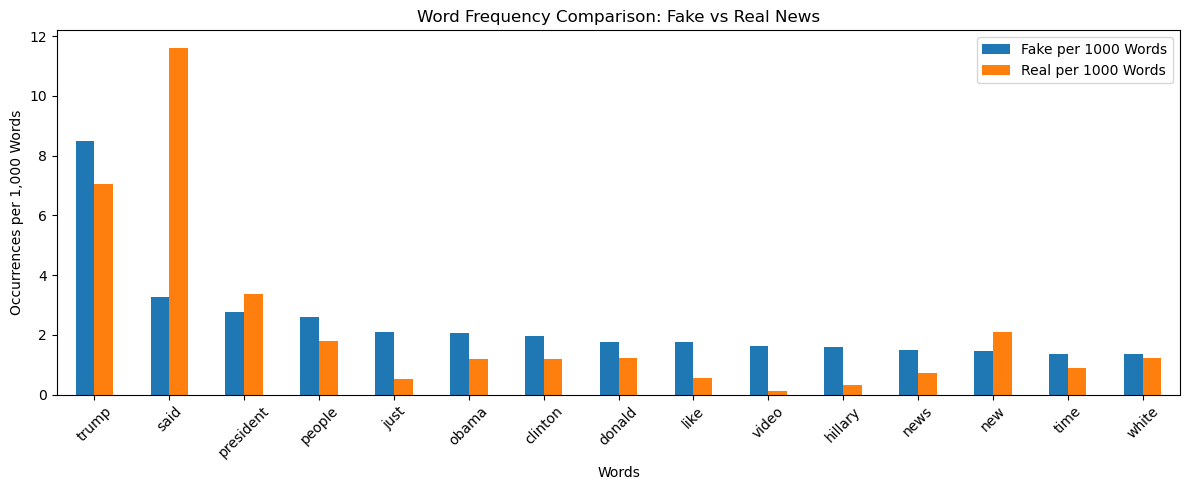

In [9]:
# Compare Word Frequencies Visually
fake_common_words.plot(x="Word", y=["Fake per 1000 Words", "Real per 1000 Words"], kind="bar", figsize=(12, 5))

plt.title("Word Frequency Comparison: Fake vs Real News")
plt.xlabel("Words")
plt.ylabel("Occurrences per 1,000 Words")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# TF-IDF Analysis
tfidf_vectorizer = TfidfVectorizer(stop_words="english", max_features=5000, min_df=5, max_df=0.8)

tfidf_matrix = tfidf_vectorizer.fit_transform(news["news_text"])

tfidf_words = tfidf_vectorizer.get_feature_names_out()

In [11]:
# Compare Average TF-IDF Scores
fake_tfidf = tfidf_matrix[fake_mask].mean(axis=0).A1
real_tfidf = tfidf_matrix[real_mask].mean(axis=0).A1

tfidf_result = pd.DataFrame({
    "Word": tfidf_words,
    "Fake Average TF-IDF": fake_tfidf,
    "Real Average TF-IDF": real_tfidf
})

tfidf_result["TF-IDF Difference"] = (
    tfidf_result["Fake Average TF-IDF"]
    - tfidf_result["Real Average TF-IDF"]
)

tfidf_result.head()

,Word,Fake Average TF-IDF,Real Average TF-IDF,TF-IDF Difference
0,00,0.001999,0.000241,0.001758
1,000,0.006784,0.009001,-0.002216
2,10,0.004768,0.005168,-0.000401
3,100,0.003162,0.002992,0.000170
4,11,0.004482,0.003017,0.001465


In [12]:
# Identify Words with Higher TF-IDF Scores in Fake News
fake_distinctive_words = tfidf_result.sort_values(by="TF-IDF Difference", ascending=False).head(15)

fake_distinctive_words.round(4)

,Word,Fake Average TF-IDF,Real Average TF-IDF,TF-IDF Difference
4795,video,0.0322,0.0012,0.0311
4665,trump,0.0804,0.0529,0.0275
2157,hillary,0.0269,0.0042,0.0227
2505,just,0.0226,0.0044,0.0182
2676,like,0.0198,0.0048,0.0150
4872,watch,0.0157,0.0008,0.0149
935,com,0.0147,0.0003,0.0144
3096,obama,0.0276,0.0132,0.0143
897,clinton,0.0282,0.0139,0.0143
4689,twitter,0.0173,0.0043,0.0130


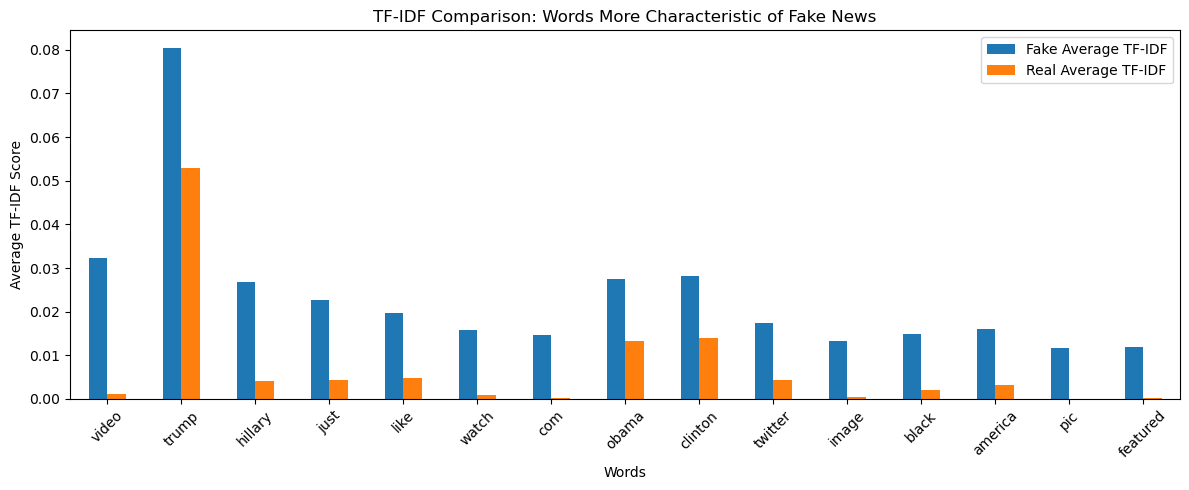

In [13]:
# TF-IDF Comparison
fake_distinctive_words.plot(x="Word", y=["Fake Average TF-IDF", "Real Average TF-IDF"], kind="bar", figsize=(12, 5))

plt.title("TF-IDF Comparison: Words More Characteristic of Fake News")
plt.xlabel("Words")
plt.ylabel("Average TF-IDF Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()